# AI投稿監視掲示板：データ分析からBERT学習まで

`toxic_dataset_augmented.csv`（列：`text`, `category`）を読み込み、データの確認・前処理・データ分割・日本語BERTの学習・評価・モデル保存までを行うノートブックです。

**今回の学習方式：8クラスの単一ラベル分類（multiclass classification）**

各文章には `適切` または7つの不適切カテゴリのうち、1つのカテゴリが付与されている前提です。モデルは文章ごとに1つのカテゴリを予測します。

> 注意：以前のFlask側 `moderation_model.py` が7カテゴリを独立に判定するマルチラベル方式（sigmoid）になっている場合、このノートブックで学習するモデル（8クラス・softmax）とは推論処理が異なります。Flaskへ組み込む際は、モデルと推論コードの方式をそろえてください。

## 1. ライブラリの読み込み

In [20]:
import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import japanize_matplotlib

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

## 2. CSVの読み込み

In [2]:
# CSVの場所に合わせて変更してください。
# 例：ノートブックが notebooks/ にあり、CSVが data/processed/ にある場合
CSV_PATH = Path("../data/processed/toxic_dataset_augmented.csv")

df = pd.read_csv(CSV_PATH, encoding="utf-8-sig")

print("データ形状:", df.shape)
display(df.head())
print("列名:", df.columns.tolist())

データ形状: (529, 2)


,text,category
0,いわゆる天使だろ,適切
1,底知れないカリスマ性があるよな,適切
2,ありがとう,適切
3,地味にこれが一番きつい,適切
4,ヤクザより怖い,差別


列名: ['text', 'category']


## 3. データの基本情報・欠損値・重複の確認

In [3]:
display(df.info())
print("\n欠損値数:")
display(df.isna().sum())

print("\n完全重複行数:", df.duplicated().sum())
print("textの重複数:", df["text"].duplicated().sum())

print("\nカテゴリ一覧:")
display(sorted(df["category"].dropna().unique().tolist()))

<class 'pandas.DataFrame'>
RangeIndex: 529 entries, 0 to 528
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----
 0   text      529 non-null    str  
 1   category  529 non-null    str  
dtypes: str(2)
memory usage: 34.3 KB


None


欠損値数:


text        0
category    0
dtype: int64


完全重複行数: 0
textの重複数: 0

カテゴリ一覧:


['偏向表現', '出会い・プライバシー侵害', '卑語', '差別', '猥褻', '迷惑行為', '違法行為', '適切']

In [4]:
# 学習に必要な列があることを確認
required_columns = {"text", "category"}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f"必要な列がありません: {missing_columns}")

# 空の文章・カテゴリを除外し、型を文字列に統一
df = df[["text", "category"]].copy()
df = df.dropna(subset=["text", "category"])
df["text"] = df["text"].astype(str).str.strip()
df["category"] = df["category"].astype(str).str.strip()
df = df[(df["text"] != "") & (df["category"] != "")].reset_index(drop=True)

print("前処理後のデータ形状:", df.shape)
print("重複行数:", df.duplicated().sum())

前処理後のデータ形状: (529, 2)
重複行数: 0


## 4. カテゴリ別件数の分析

,count
category,
適切,319
迷惑行為,51
偏向表現,27
出会い・プライバシー侵害,27
違法行為,27
差別,26
猥褻,26
卑語,26


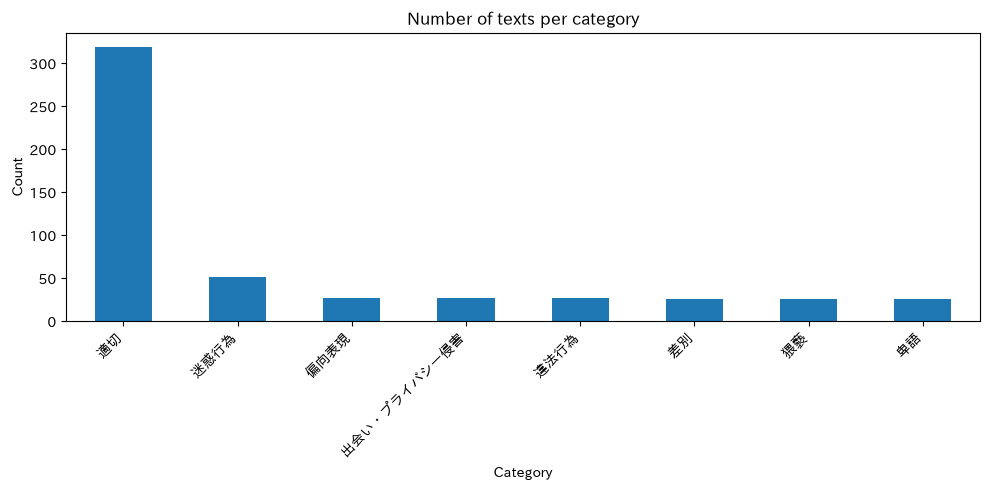

In [21]:
category_counts = df["category"].value_counts()
display(category_counts.rename_axis("category").to_frame("count"))

ax = category_counts.plot(kind="bar", figsize=(10, 5))
ax.set_title("Number of texts per category")
ax.set_xlabel("Category")
ax.set_ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 分析時の確認ポイント
- `適切` と不適切カテゴリの件数差を確認する。
- 件数が少ないカテゴリは、学習・評価結果が不安定になりやすい。
- 人工生成した追加データが含まれるため、似た文章や不自然なラベルがないか、学習前に目視確認する。
- 同じ文章の重複がある場合、重複行をそのまま別々の分割に入れると評価が過大になる可能性がある。重複の扱いは内容を確認して判断する。

## 5. ラベルの定義

In [6]:
# 出力ラベルの順序を固定
preferred_labels = [
    "適切",
    "卑語",
    "差別",
    "迷惑行為",
    "猥褻",
    "出会い・プライバシー侵害",
    "違法行為",
    "偏向表現",
]

observed_labels = set(df["category"].unique())
unknown_labels = observed_labels - set(preferred_labels)
if unknown_labels:
    raise ValueError(f"想定外のカテゴリがあります: {unknown_labels}")

labels = [label for label in preferred_labels if label in observed_labels]
label2id = {label: idx for idx, label in enumerate(labels)}
id2label = {idx: label for label, idx in label2id.items()}

df["label"] = df["category"].map(label2id).astype(int)

print("ラベル対応表:")
display(pd.DataFrame({"category": labels, "label_id": range(len(labels))}))
print("クラス数:", len(labels))

ラベル対応表:


,category,label_id
0,適切,0
1,卑語,1
2,差別,2
3,迷惑行為,3
4,猥褻,4
5,出会い・プライバシー侵害,5
6,違法行為,6
7,偏向表現,7


クラス数: 8


## 6. 学習・検証・テストデータへの分割

In [7]:
# 80% train / 10% validation / 10% test
train_df, temp_df = train_test_split(
    df,
    test_size=0.2,
    random_state=SEED,
    stratify=df["label"],
)

valid_df, test_df = train_test_split(
    temp_df,
    test_size=0.5,
    random_state=SEED,
    stratify=temp_df["label"],
)

for name, split_df in [
    ("train", train_df),
    ("validation", valid_df),
    ("test", test_df),
]:
    print(f"\n=== {name}: {len(split_df)}件 ===")
    display(
        split_df["category"]
        .value_counts()
        .reindex(labels, fill_value=0)
        .rename_axis("category")
        .to_frame("count")
    )


=== train: 423件 ===


,count
category,
適切,255
卑語,21
差別,21
迷惑行為,41
猥褻,21
出会い・プライバシー侵害,21
違法行為,22
偏向表現,21



=== validation: 53件 ===


,count
category,
適切,32
卑語,2
差別,3
迷惑行為,5
猥褻,2
出会い・プライバシー侵害,3
違法行為,3
偏向表現,3



=== test: 53件 ===


,count
category,
適切,32
卑語,3
差別,2
迷惑行為,5
猥褻,3
出会い・プライバシー侵害,3
違法行為,2
偏向表現,3


## 7. Hugging Face Datasetとトークナイザー

In [8]:
from datasets import Dataset
from transformers import AutoTokenizer

MODEL_NAME = "cl-tohoku/bert-base-japanese-v3"

train_dataset = Dataset.from_pandas(
    train_df[["text", "label"]].reset_index(drop=True)
)
valid_dataset = Dataset.from_pandas(
    valid_df[["text", "label"]].reset_index(drop=True)
)
test_dataset = Dataset.from_pandas(
    test_df[["text", "label"]].reset_index(drop=True)
)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
print(tokenizer)

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


BertJapaneseTokenizer(name_or_path='cl-tohoku/bert-base-japanese-v3', vocab_size=32768, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	3: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	4: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [9]:
MAX_LENGTH = 128

def tokenize_function(examples):
    return tokenizer(
        examples["text"],
        truncation=True,
        max_length=MAX_LENGTH,
    )

tokenized_train = train_dataset.map(tokenize_function, batched=True)
tokenized_valid = valid_dataset.map(tokenize_function, batched=True)
tokenized_test = test_dataset.map(tokenize_function, batched=True)

print(tokenized_train[0])

Parameter 'function'=<function tokenize_function at 0xf12fa262a340> of the transform datasets.arrow_dataset.Dataset._map_single couldn't be hashed properly, a random hash was used instead. Make sure your transforms and parameters are serializable with pickle or dill for the dataset fingerprinting and caching to work. If you reuse this transform, the caching mechanism will consider it to be different from the previous calls and recompute everything. This warning is only shown once. Subsequent hashing failures won't be shown.
Map: 100%|███████████████████████████████████████████████████████████████████████████████████████████| 53/53 [00:00<00:00, 5435.43 examples/s]

{'text': 'この衣装カッコいい、可愛いから欲しいってやつ以外もう課金要素ないだろ', 'label': 3, 'input_ids': [2, 12499, 16779, 29623, 13700, 384, 27514, 12488, 19508, 16777, 30951, 12943, 13782, 30965, 14253, 12494, 450, 7111, 3], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


## 8. モデルの読み込み

In [10]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id,
)

print("モデルの出力クラス数:", model.config.num_labels)

Loading weights: 100%|███████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 26438.60it/s]
[transformers] BertForSequenceClassification LOAD REPORT from: cl-tohoku/bert-base-japanese-v3
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.seq_relationship.bias                  | UNEXPECTED | 
cls.predictions.decoder.bias               | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.decoder.weight             | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING  

モデルの出力クラス数: 8


## 9. 学習設定と評価指標

In [14]:
from transformers import TrainingArguments, Trainer, DataCollatorWithPadding
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def compute_metrics(eval_pred):
    logits, true_labels = eval_pred
    pred_labels = np.argmax(logits, axis=-1)

    precision_macro, recall_macro, f1_macro, _ = (
        precision_recall_fscore_support(
            true_labels,
            pred_labels,
            average="macro",
            zero_division=0,
        )
    )
    precision_weighted, recall_weighted, f1_weighted, _ = (
        precision_recall_fscore_support(
            true_labels,
            pred_labels,
            average="weighted",
            zero_division=0,
        )
    )

    return {
        "accuracy": accuracy_score(true_labels, pred_labels),
        "precision_macro": precision_macro,
        "recall_macro": recall_macro,
        "f1_macro": f1_macro,
        "precision_weighted": precision_weighted,
        "recall_weighted": recall_weighted,
        "f1_weighted": f1_weighted,
    }

OUTPUT_DIR = "./models/toxic-bert-multiclass"

training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,
    eval_strategy="epoch",
    save_strategy="epoch",

    learning_rate=2e-5,
    per_device_train_batch_size=2,
    per_device_eval_batch_size=2,
    gradient_accumulation_steps=2,  # 実効バッチサイズは4相当
    num_train_epochs=3,
    weight_decay=0.01,

    gradient_checkpointing=True,    # メモリ使用量を削減
    logging_steps=10,
    load_best_model_at_end=True,
    metric_for_best_model="eval_f1_macro",
    greater_is_better=True,
    save_total_limit=2,
    report_to="none",
    seed=SEED,
)

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

## 10. 学習

In [16]:
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_valid,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

train_result = trainer.train()
print(train_result)

Epoch,Training Loss,Validation Loss,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted
1,2.293808,1.075724,0.660377,0.147606,0.250000,0.184599,0.439382,0.660377,0.526869
2,2.901554,0.968185,0.698113,0.436012,0.391927,0.395206,0.582435,0.698113,0.624822
3,1.358640,0.938390,0.716981,0.500762,0.433594,0.438307,0.631040,0.716981,0.653764


Writing model shards: 100%|█████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:01<00:00,  1.53s/it]
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|█████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:00<00:00,  1.46it/s]
/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
Writing model shards: 100%|█████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.01s/it]


TrainOutput(global_step=318, training_loss=2.0631304177098304, metrics={'train_runtime': 424.9178, 'train_samples_per_second': 2.986, 'train_steps_per_second': 0.748, 'total_flos': 8798249863680.0, 'train_loss': 2.0631304177098304, 'epoch': 3.0})


## 11. テストデータで評価

In [17]:
test_result = trainer.evaluate(tokenized_test)
print(test_result)

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Training Loss,Validation Loss,Epoch,Accuracy,Precision Macro,Recall Macro,F1 Macro,Precision Weighted,Recall Weighted,F1 Weighted
1.358640,0.774924,3,0.773585,0.518750,0.520833,0.495337,0.653774,0.773585,0.698098


{'eval_loss': 0.7749244570732117, 'eval_accuracy': 0.7735849056603774, 'eval_precision_macro': 0.51875, 'eval_recall_macro': 0.5208333333333333, 'eval_f1_macro': 0.4953373015873016, 'eval_precision_weighted': 0.6537735849056605, 'eval_recall_weighted': 0.7735849056603774, 'eval_f1_weighted': 0.6980982330038933}


In [18]:
test_predictions = trainer.predict(tokenized_test)
test_logits = test_predictions.predictions
y_true = test_predictions.label_ids
y_pred = np.argmax(test_logits, axis=-1)

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
    target_names=labels,
    zero_division=0,
    digits=3,
))

/home/kobat/bbs-with-AI-monitoring/.env/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


              precision    recall  f1-score   support

          適切      0.800     1.000     0.889        32
          卑語      0.000     0.000     0.000         3
          差別      0.000     0.000     0.000         2
        迷惑行為      0.000     0.000     0.000         5
          猥褻      0.600     1.000     0.750         3
出会い・プライバシー侵害      0.750     1.000     0.857         3
        違法行為      1.000     0.500     0.667         2
        偏向表現      1.000     0.667     0.800         3

    accuracy                          0.774        53
   macro avg      0.519     0.521     0.495        53
weighted avg      0.654     0.774     0.698        53



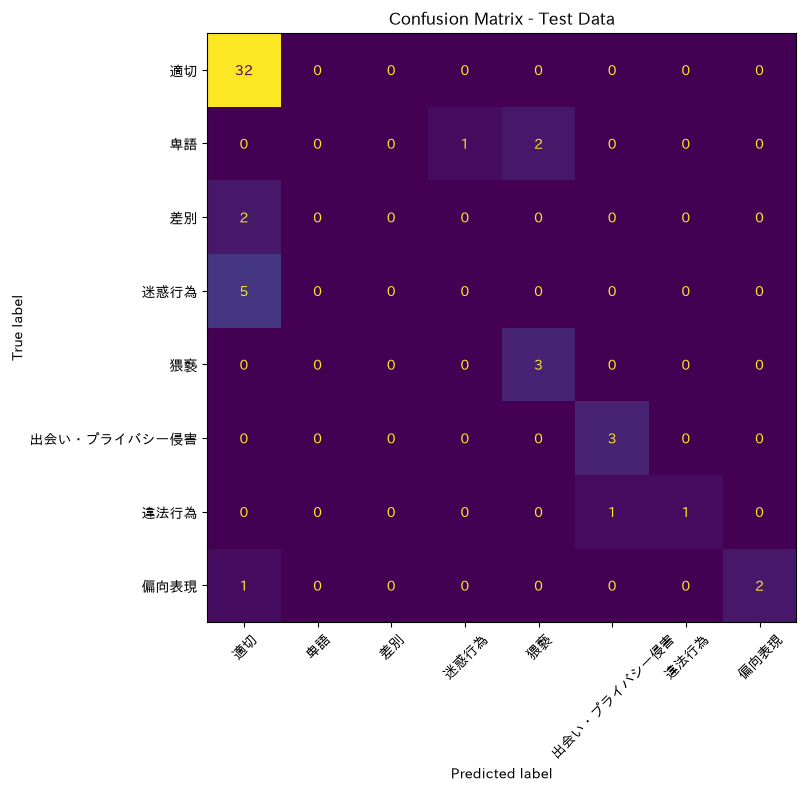

In [22]:
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(labels))),
)

fig, ax = plt.subplots(figsize=(10, 8))
display_obj = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels,
)
display_obj.plot(
    ax=ax,
    xticks_rotation=45,
    values_format="d",
    colorbar=False,
)
plt.title("Confusion Matrix - Test Data")
plt.tight_layout()
plt.show()

## 12. 誤分類例の確認

In [23]:
error_df = test_df[["text", "category"]].copy().reset_index(drop=True)
error_df["true_category"] = [id2label[int(x)] for x in y_true]
error_df["predicted_category"] = [id2label[int(x)] for x in y_pred]
error_df["correct"] = y_true == y_pred

display(error_df[~error_df["correct"]].head(30))

,text,category,true_category,predicted_category,correct
1,こんな出来で金取るとか舐めてんのか,卑語,卑語,猥褻,False
2,図星か落ち着いて,迷惑行為,迷惑行為,適切,False
10,京都人何様なのお,迷惑行為,迷惑行為,適切,False
15,許可取れてるからって所々舐めくさっとるよな,卑語,卑語,猥褻,False
30,まだ騙されとる奴おるんか,迷惑行為,迷惑行為,適切,False
31,いい加減な仕事しやがって,卑語,卑語,迷惑行為,False
38,これ心臓マヒで死ぬだろ,偏向表現,偏向表現,適切,False
39,お爺さんかわいそう,差別,差別,適切,False
42,他人のアカウントに無断でログインしてやった,違法行為,違法行為,出会い・プライバシー侵害,False
44,二重国籍ですらない,差別,差別,適切,False


## 13. 学習済みモデルとラベル情報の保存

In [ ]:
# 最良モデルとトークナイザーを保存
trainer.save_model(OUTPUT_DIR)
tokenizer.save_pretrained(OUTPUT_DIR)

# ラベル対応表もJSONで保存
with open( ".." / Path(OUTPUT_DIR) / "label_mapping.json", "w", encoding="utf-8") as f:
    json.dump(
        {
            "label2id": label2id,
            "id2label": {str(k): v for k, v in id2label.items()},
            "labels": labels,
        },
        f,
        ensure_ascii=False,
        indent=2,
    )

print(f"モデルを保存しました: {OUTPUT_DIR}")

Writing model shards: 100%|█████████████████████████████████████████████████████████████████████████████████████| 1/1 [00:02<00:00,  2.08s/it]

モデルを保存しました: ./models/toxic-bert-multiclass
